# IR 2 — Pre-optimized functional-group classifier

Run this after the carpentry notebook. This static notebook deliberately uses one selected, tuned algorithm: a regularized multi-layer perceptron for multi-label IR classification. It has stratified train/validation/test partitions, training-only scaling, class-imbalance-weighted binary cross-entropy, ReLU hidden layers, AdamW, learning-rate scheduling, early stopping, TensorBoard logging, periodic checkpoints, validation-only threshold tuning, and an untouched final test evaluation.


In [1]:
from pathlib import Path
import random
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from iterstrat.ml_stratifiers import MultilabelStratifiedShuffleSplit
from sklearn.metrics import classification_report, f1_score
from sklearn.preprocessing import StandardScaler
from torch import nn
from torch.utils.data import DataLoader, TensorDataset
from torch.utils.tensorboard import SummaryWriter

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available(): torch.cuda.manual_seed_all(SEED)
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
DATA_FILE = Path('outputs/carpentry/IR_model_ready.parquet')
OUTPUT_DIR = Path('outputs/optimized_training'); OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
CHECKPOINT = OUTPUT_DIR / 'best_ir_mlp.pt'
CHECKPOINT_DIR = OUTPUT_DIR / 'checkpoints'; CHECKPOINT_DIR.mkdir(exist_ok=True)
TENSORBOARD_DIR = OUTPUT_DIR / 'tensorboard'
SAVE_EVERY_EPOCHS = 25
LABELS = ['Vinylic', 'Arene', 'Alcohol', 'Ether', 'Amine', 'Nitrile', 'Aldehyde', 'Ketone', 'CarboxylAcid', 'Ester', 'Amide', 'AcidChloride']
if not DATA_FILE.exists(): raise FileNotFoundError(f'Run the carpentry notebook first: {DATA_FILE}')
data = pd.read_parquet(DATA_FILE)
X = np.log1p(np.vstack(data.IR.map(lambda values: np.asarray(values, dtype=np.float32))))
y = data[LABELS].to_numpy(dtype=np.int64)
if X.shape != (len(data), 500) or not np.isfinite(X).all(): raise ValueError('Expected finite 500-point IR arrays.')
print(f'Rows={len(data):,}, features={X.shape[1]}, labels={len(LABELS)}, device={DEVICE}')


Rows=5,669, features=500, labels=12, device=cpu


In [2]:
split = MultilabelStratifiedShuffleSplit(n_splits=1, test_size=0.30, random_state=SEED)
train_index, temporary_index = next(split.split(X, y))
split = MultilabelStratifiedShuffleSplit(n_splits=1, test_size=0.50, random_state=SEED)
validation_relative, test_relative = next(split.split(X[temporary_index], y[temporary_index]))
validation_index, test_index = temporary_index[validation_relative], temporary_index[test_relative]

X_train, X_validation, X_test = X[train_index], X[validation_index], X[test_index]
y_train, y_validation, y_test = y[train_index], y[validation_index], y[test_index]
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train).astype(np.float32)
X_validation = scaler.transform(X_validation).astype(np.float32)
X_test = scaler.transform(X_test).astype(np.float32)
print(f'Train/validation/test: {len(X_train):,} / {len(X_validation):,} / {len(X_test):,}')


Train/validation/test: 3,968 / 850 / 851


In [3]:
class SpectralMLP(nn.Module):
    def __init__(self, inputs, outputs):
        super().__init__()
        self.network = nn.Sequential(
            nn.Linear(inputs, 256), nn.ReLU(), nn.BatchNorm1d(256), nn.Dropout(0.25),
            nn.Linear(256, 128), nn.ReLU(), nn.BatchNorm1d(128), nn.Dropout(0.15),
            nn.Linear(128, outputs))
    def forward(self, inputs): return self.network(inputs)

def tensor(values): return torch.tensor(values, dtype=torch.float32, device=DEVICE)
train_loader = DataLoader(TensorDataset(tensor(X_train), tensor(y_train)), batch_size=128, shuffle=True)
validation_features, validation_targets = tensor(X_validation), tensor(y_validation)
test_features = tensor(X_test)
positive = y_train.sum(0); negative = len(y_train) - positive
pos_weight = torch.tensor(np.clip(negative / np.maximum(positive, 1), 1, 20), dtype=torch.float32, device=DEVICE)
model = SpectralMLP(500, len(LABELS)).to(DEVICE)
criterion = nn.BCEWithLogitsLoss(pos_weight=pos_weight)
optimizer = torch.optim.AdamW(model.parameters(), lr=1e-3, weight_decay=1e-4)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', factor=0.5, patience=8)
writer = SummaryWriter(log_dir=str(TENSORBOARD_DIR))
writer.add_text('model', str(model), 0)
writer.add_text('configuration', f'optimizer=AdamW; initial_lr=0.001; scheduler=ReduceLROnPlateau; class_weighted_BCE=True; checkpoint_every={SAVE_EVERY_EPOCHS}', 0)
print(f'TensorBoard logs: {TENSORBOARD_DIR}')


TensorBoard logs: outputs\optimized_training\tensorboard


In [4]:
MAX_EPOCHS, PATIENCE = 250, 25
best_loss, stale_epochs, history = float('inf'), 0, []
for epoch in range(1, MAX_EPOCHS + 1):
    model.train(); batch_losses = []
    for features, targets in train_loader:
        optimizer.zero_grad(set_to_none=True); loss = criterion(model(features), targets)
        loss.backward(); torch.nn.utils.clip_grad_norm_(model.parameters(), 5.0); optimizer.step()
        batch_losses.append(loss.item())
    model.eval()
    with torch.no_grad(): validation_loss = criterion(model(validation_features), validation_targets).item()
    scheduler.step(validation_loss)
    train_loss, learning_rate = float(np.mean(batch_losses)), optimizer.param_groups[0]['lr']
    history.append((epoch, train_loss, validation_loss, learning_rate))
    writer.add_scalar('loss/train', train_loss, epoch)
    writer.add_scalar('loss/validation', validation_loss, epoch)
    writer.add_scalar('learning_rate', learning_rate, epoch)
    checkpoint_payload = {'state_dict': model.state_dict(), 'labels': LABELS, 'scaler_mean': scaler.mean_.tolist(), 'scaler_scale': scaler.scale_.tolist(), 'epoch': epoch, 'validation_loss': validation_loss}
    if epoch % SAVE_EVERY_EPOCHS == 0: torch.save(checkpoint_payload, CHECKPOINT_DIR / f'epoch_{epoch:03d}.pt')
    if validation_loss < best_loss - 1e-4:
        best_loss, stale_epochs = validation_loss, 0
        torch.save(checkpoint_payload, CHECKPOINT)
    else: stale_epochs += 1
    if epoch == 1 or epoch % 20 == 0: print(f'Epoch {epoch}: train={train_loss:.4f}, validation={validation_loss:.4f}, lr={learning_rate:.2e}')
    if stale_epochs >= PATIENCE:
        print(f'Early stopped; retained validation-best checkpoint from epoch {torch.load(CHECKPOINT, map_location="cpu", weights_only=True)["epoch"]}.')
        break
best_checkpoint = torch.load(CHECKPOINT, map_location=DEVICE, weights_only=True)
model.load_state_dict(best_checkpoint['state_dict'])
print(f"Restored validation-best model: epoch {best_checkpoint['epoch']} (loss={best_checkpoint['validation_loss']:.4f}).")


Epoch 1: train=0.7926, validation=0.6563, lr=1.00e-03


Epoch 20: train=0.1094, validation=0.2843, lr=1.00e-03


Epoch 40: train=0.0483, validation=0.3088, lr=2.50e-04


Early stopped; retained validation-best checkpoint from epoch 16.
Restored validation-best model: epoch 16 (loss=0.2662).


,label,validation threshold,test precision,test recall,test F1,test support
0,Vinylic,0.81,0.851,0.746,0.795,130.0
1,Arene,0.41,0.955,0.976,0.966,460.0
2,Alcohol,0.73,0.977,0.959,0.968,218.0
3,Ether,0.44,0.922,0.930,0.926,230.0
4,Amine,0.77,0.924,0.924,0.924,92.0
5,Nitrile,0.80,0.604,0.744,0.667,39.0
6,Aldehyde,0.86,0.944,0.773,0.850,22.0
7,Ketone,0.75,0.811,0.890,0.849,82.0
8,CarboxylAcid,0.88,0.964,0.855,0.906,62.0
9,Ester,0.62,0.951,0.960,0.956,101.0


Test macro F1: 0.871 | TensorBoard: tensorboard --logdir outputs\optimized_training\tensorboard


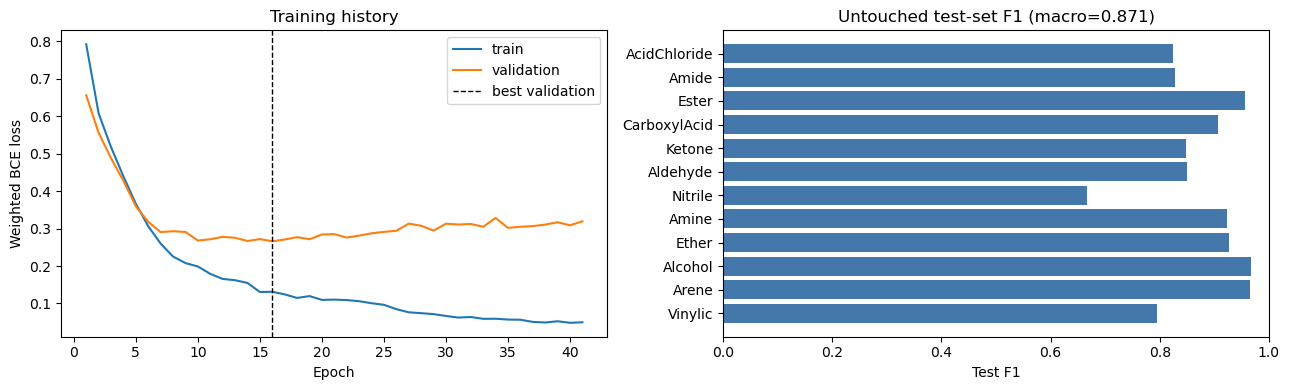

In [5]:
model.eval()
with torch.no_grad():
    validation_probability = torch.sigmoid(model(validation_features)).cpu().numpy()
    test_probability = torch.sigmoid(model(test_features)).cpu().numpy()
threshold_grid = np.linspace(0.10, 0.90, 81)
thresholds = np.array([threshold_grid[np.argmax([f1_score(y_validation[:, index], validation_probability[:, index] >= threshold, zero_division=0) for threshold in threshold_grid])] for index in range(len(LABELS))])
test_prediction = (test_probability >= thresholds).astype(int)
macro_f1 = f1_score(y_test, test_prediction, average='macro', zero_division=0)
report = classification_report(y_test, test_prediction, target_names=LABELS, output_dict=True, zero_division=0)
per_label = [report[label]['f1-score'] for label in LABELS]
summary = pd.DataFrame({'label': LABELS, 'validation threshold': thresholds, 'test precision': [report[label]['precision'] for label in LABELS], 'test recall': [report[label]['recall'] for label in LABELS], 'test F1': per_label, 'test support': [report[label]['support'] for label in LABELS]})
display(summary.round(3))
summary.to_csv(OUTPUT_DIR / 'test_metrics_by_label.csv', index=False)
pd.DataFrame({'label': LABELS, 'validation threshold': thresholds}).to_csv(OUTPUT_DIR / 'thresholds.csv', index=False)
writer.add_scalar('metrics/test_macro_f1', macro_f1, best_checkpoint['epoch'])
writer.flush(); writer.close()
print(f'Test macro F1: {macro_f1:.3f} | TensorBoard: tensorboard --logdir {TENSORBOARD_DIR}')

history_frame = pd.DataFrame(history, columns=['epoch', 'train loss', 'validation loss', 'learning rate'])
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].plot(history_frame.epoch, history_frame['train loss'], label='train'); axes[0].plot(history_frame.epoch, history_frame['validation loss'], label='validation'); axes[0].axvline(best_checkpoint['epoch'], color='black', ls='--', lw=1, label='best validation'); axes[0].legend(); axes[0].set(title='Training history', xlabel='Epoch', ylabel='Weighted BCE loss')
axes[1].barh(LABELS, per_label, color='#4477AA'); axes[1].set(xlim=(0, 1), xlabel='Test F1', title=f'Untouched test-set F1 (macro={macro_f1:.3f})')
fig.tight_layout(); fig.savefig(OUTPUT_DIR / 'model_summary.png', dpi=160, bbox_inches='tight'); plt.show()


The validation-best checkpoint, periodic weight snapshots, TensorBoard event log, selected thresholds, label-level metrics, and summary image are saved under `outputs/optimized_training/`. To inspect learning curves interactively, run `tensorboard --logdir outputs/optimized_training/tensorboard` from this folder. The final test set was not used for scaling, early stopping, or threshold selection.
